# 03 — Seleção e transformação das variáveis

**Enunciado etapa 3** \
Seleção e transformação das variáveis: defina a codificação das variáveis
categóricas e a necessidade de padronização das variáveis numéricas. Investigue
possíveis redundâncias e avalie se a seleção ou criação de variáveis contribui para
os resultados.

Todas as decisões deste notebook são tomadas **apenas com o treino** (`train.csv`)

**Observação**:
Para o teste dos modelos, será feito um pipeline de testes de performance de cada conjunto de variáveis. Inicialmente testarei o conjunto de todas as variáveis iniciais. Esse notebook é para realizar a Seleção de variáveis e Engenharia de atributos, etapas que serão parte do pipeline.

**Saídas deste notebook**:
- `data/processed/feature_set.json` — conjuntos de variáveis escolhidos (`base` e `engenharia`)
- `data/processed/train_fe.csv` e `test_fe.csv` — treino e teste com as variáveis criadas (regras fixas, sem nenhum parâmetro estimado)

In [125]:
# Imports
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

In [126]:
# Leitura do treino
train = pd.read_csv("../data/processed/train.csv")
TARGET = "Churn"
X = train.drop(columns=["customerID", TARGET])
y = train[TARGET]
print(X.shape, f"taxa de churn no treino = {y.mean():.1%}")
X.head()

(5634, 19) taxa de churn no treino = 26.5%


,is_male,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,1,0,0,0,35,0,0,DSL,0,0,1,0,1,1,Month-to-month,0,Electronic check,49.20,1701.65
1,1,0,1,1,15,1,0,Fiber optic,1,0,0,0,0,0,Month-to-month,0,Mailed check,75.10,1151.55
2,1,0,1,1,13,0,0,DSL,1,1,0,1,0,0,Two year,0,Mailed check,40.55,590.35
3,0,0,1,0,26,1,0,DSL,0,1,1,0,1,1,Two year,1,Credit card (automatic),73.50,1905.70
4,1,0,1,1,1,1,0,DSL,0,0,0,0,0,0,Month-to-month,0,Electronic check,44.55,44.55


Separação das colunas em grupos, de acordo com o tratamento feito no notebook 01

In [127]:
# Grupos de colunas
NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAS = ["InternetService", "Contract", "PaymentMethod"]
BINARIAS = [c for c in X.columns if c not in NUMERICAS + CATEGORICAS]
SERVICOS_ADICIONAIS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                       "TechSupport", "StreamingTV", "StreamingMovies"]
print("Numéricas: ", NUMERICAS)
print("Categóricas:", CATEGORICAS)
print("Binárias:  ", BINARIAS)

Numéricas:  ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas: ['InternetService', 'Contract', 'PaymentMethod']
Binárias:   ['is_male', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']


## 1. Codificação das variáveis categóricas

- As **13 variáveis binárias** já foram convertidas para 0/1 no notebook 01 (incluindo os serviços de internet e `MultipleLines`, depois de juntar "No internet service"/"No phone service" com "No"). Não precisam de mais nenhuma transformação.
- Restam as variáveis `InternetService`, `Contract` e `PaymentMethod`, que possuem mais de duas categorias. Por isso uso **one-hot encoding** nelas

In [128]:
for col in CATEGORICAS:
    print(X[col].value_counts().to_string(), "\n")

InternetService
Fiber optic    2483
DSL            1937
No             1214 

Contract
Month-to-month    3102
Two year          1359
One year          1173 

PaymentMethod
Electronic check             1891
Mailed check                 1286
Bank transfer (automatic)    1244
Credit card (automatic)      1213 



Usarei `drop="first"` para evitar problema de colinearidade nos coeficientes da Regressão Logística

In [129]:
def fazer_preprocessador(numericas, binarias, categoricas, escalar=True):
    # One-hot nas categóricas, padronização opcional nas numéricas e binárias sem alteração
    return ColumnTransformer([
        ("num", StandardScaler() if escalar else "passthrough", numericas),
        ("bin", "passthrough", binarias),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categoricas),
    ], verbose_feature_names_out=False)


# Base codificada (sem padronização) só para inspecionar as colunas
prep = fazer_preprocessador(NUMERICAS, BINARIAS, CATEGORICAS, escalar=False).set_output(transform="pandas")
X_enc = prep.fit_transform(X)
print(f"{X.shape[1]} variáveis originais -> {X_enc.shape[1]} colunas após a codificação")
print([c for c in X_enc.columns if c.startswith(tuple(CATEGORICAS))])

19 variáveis originais -> 23 colunas após a codificação
['InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


Categorias de referência (removidas): `InternetService = DSL`, `Contract = Month-to-month` e `PaymentMethod = Bank transfer (automatic)`.

## 2. Padronização das variáveis numéricas

In [130]:
X[NUMERICAS].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,32.49,64.93,2299.33
std,24.57,30.14,2279.20
min,0.00,18.40,0.00
25%,9.00,35.66,402.98
50%,29.00,70.50,1394.92
75%,55.00,90.00,3835.82
max,72.00,118.75,8684.80


As três numéricas têm escalas muito diferentes: `tenure` vai de 0 a 72, `MonthlyCharges` de ~18 a ~119 e `TotalCharges` de 0 a ~8.700, enquanto as binárias e dummies valem 0 ou 1.

- O k-NN usa distâncias. Por isso, variáveis com escala maior podem dominar o cálculo da distância. Na escala atual das variáveis, `TotalCharges` terá uma influência muito maior na distância euclidiana apenas porque está em uma escala maior.
- Regressão logística é também sensível à **escala** das variáveis: como o modelo é ajustado via otimização numérica e regularizado (penalizando o tamanho dos coeficientes), variáveis em escalas muito diferentes podem distorcer o processo de otimização e a regularização
- **Árvores** (árvore de decisão, Random Forest, Gradient Boosting) fazem cortes do tipo `x <= c`, que não mudam com transformações monótonas. Para elas, padronizar é indiferente.

Por isso, para evitar esse problema no KNN e na Regressão, usaremos **padronização** com `StandardScaler`, ajustado só no treino de cada fold, transformando cada variável para ter média 0 e desvio padrão 1:
$$
z = \frac{x - \mu}{\sigma}.
$$

Abaixo, verifico o efeito na prática com validação cruzada: o mesmo modelo com e sem padronização, nos mesmos 5 folds.

**[IA] - Tive o auxílio de IA para fazer as funções reutilizáveis abaixo, tornando o código mais limpo, e deixando os testes mais práticos de serem realizados**

In [131]:
# Protocolo de avaliação usado em todo o notebook (os mesmos 5 folds para todos os modelos)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
METRICAS = {"roc_auc": "roc_auc", "ap": "average_precision", "f1": "f1"}


def avaliar(modelo, X, y):
    # Métricas de cada fold da validação cruzada
    r = cross_validate(modelo, X, y, cv=CV, scoring=METRICAS, n_jobs=-1)
    return pd.DataFrame({m: r[f"test_{m}"] for m in METRICAS})


def resumir(resultados):
    # Média ± desvio padrão entre os folds
    g = resultados.groupby(["modelo", "configuração"])[list(METRICAS)]
    media, desvio = g.mean(), g.std()
    return media.round(3).astype(str) + " ± " + desvio.round(3).astype(str)

In [132]:
linhas = []
for nome, modelo in [("LogReg", LogisticRegression(max_iter=5000)), ("KNN", KNeighborsClassifier(n_neighbors=25))]:
    for escalar in [False, True]: # Testar com o sem StandardScaler -> True para com, False para sem
        pipe = Pipeline([("prep", fazer_preprocessador(NUMERICAS, BINARIAS, CATEGORICAS, escalar)),
                         ("modelo", modelo)])
        res = avaliar(pipe, X, y).assign(modelo=nome, configuração="padronizado" if escalar else "sem padronizar") # True para padronizado, False para sem padronizar
        linhas.append(res)
res_escala = pd.concat(linhas)
resumir(res_escala)

roc_auc             ap             f1
modelo configuração                                               
KNN    padronizado     0.834 ± 0.011   0.62 ± 0.013  0.597 ± 0.019
       sem padronizar   0.78 ± 0.011  0.579 ± 0.027  0.477 ± 0.038
LogReg padronizado     0.846 ± 0.014  0.661 ± 0.022  0.593 ± 0.034
       sem padronizar  0.846 ± 0.014  0.662 ± 0.021  0.593 ± 0.034

- Para o **KNN**, a padronização faz muita diferença. A AP sobe de 0,579 para 0,620, a ROC-AUC de 0,780 para 0,834 e o F1 de 0,477 para 0,597
- Para a **Regressão logística**, o resultado é praticamente idêntico. Mesmo assim, decido manter a padronização, pois ela ajuda na convergência e deixa os coeficientes comparáveis entre si

Portanto, seguirei usando o `StandardScaler` nas numéricas para todos os modelos

## 3. Redundâncias

### 3.1 Correlação entre as variáveis

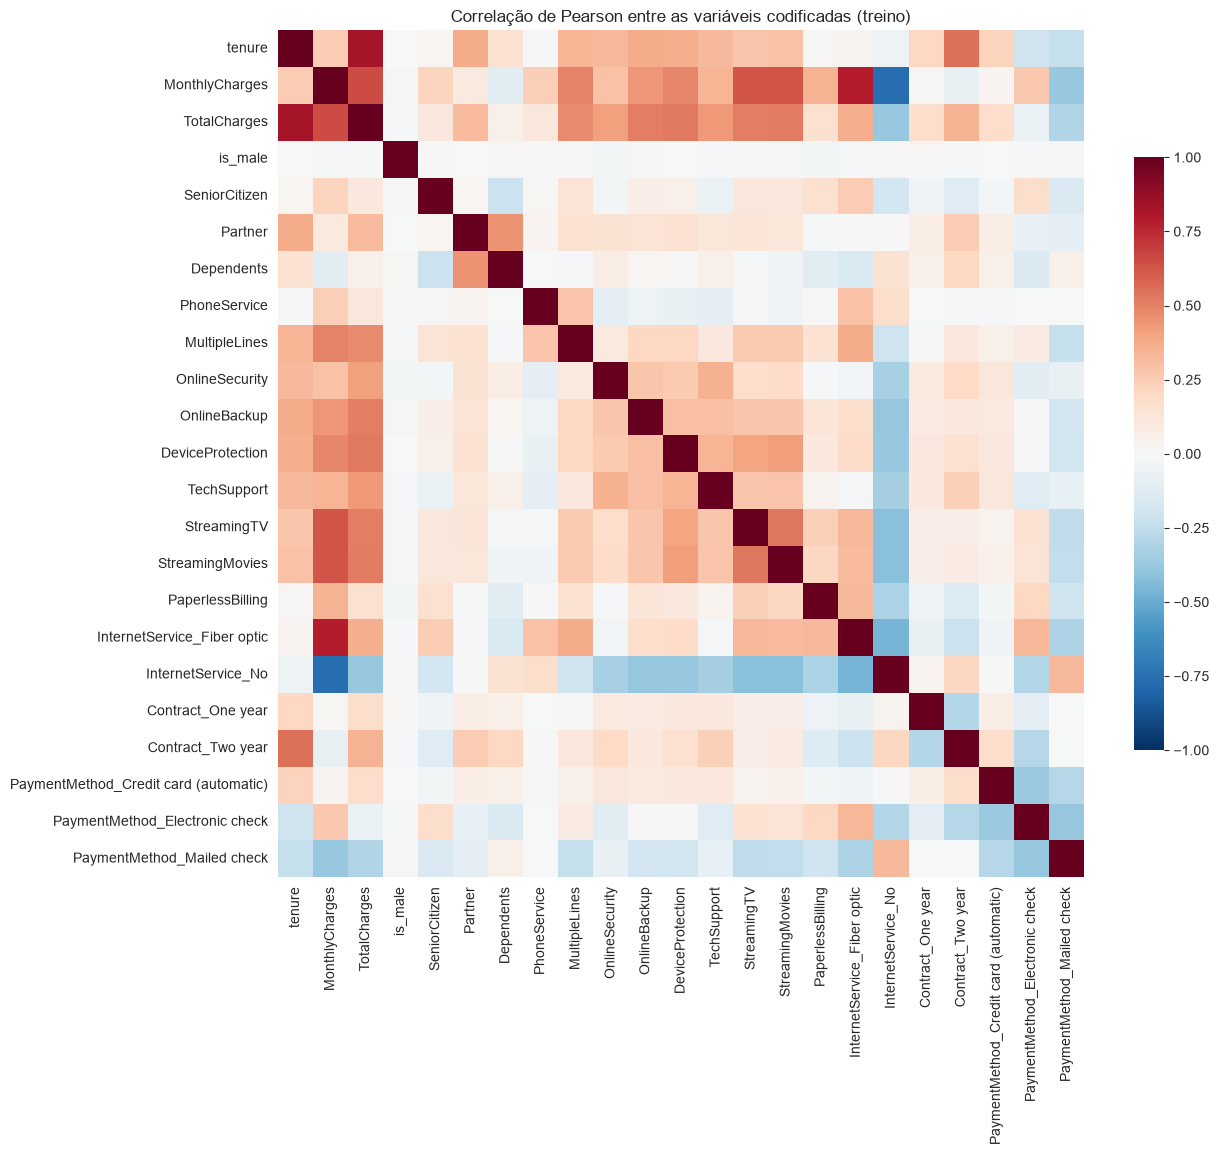

In [133]:
corr = X_enc.corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Correlação de Pearson entre as variáveis codificadas (treino)")
plt.show()

In [134]:
# Pares mais correlacionados
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pares = pares.reindex(pares.abs().sort_values(ascending=False).index)
pares[pares.abs() >= 0.5].round(3).to_frame("correlação")

correlação
tenure         TotalCharges                      0.830
MonthlyCharges InternetService_Fiber optic       0.788
               InternetService_No               -0.762
               TotalCharges                      0.654
               StreamingTV                       0.632
               StreamingMovies                   0.625
tenure         Contract_Two year                 0.555
StreamingTV    StreamingMovies                   0.536
TotalCharges   DeviceProtection                  0.528
               StreamingMovies                   0.520
               OnlineBackup                      0.514
               StreamingTV                       0.513

- `tenure` × `TotalCharges` (0,83) - já era esperado, já que `TotalCharges ≈ tenure × MonthlyCharges` (notebook 01)
- `MonthlyCharges` × tipo de internet (0,79 com fibra, −0,76 sem internet) e × streaming (~0,63) - também esperado, pois a mensalidade depende diretamente dos serviços contratados
- `tenure` × `Contract_Two year` (0,56) - clientes com contrato bianual tendem a estar há mais tempo na empresa

### 3.2 Multicolinearidade (VIF)

Para ir mais afundo na multicolinearidade, usarei a VIF (*Variance Inflation Factor*), que mede o quanto cada variável é explicada por todas as outras juntas: $VIF_j = 1 / (1 - R^2_j)$, onde $R^2_j$ vem da regressão da variável $j$ nas demais. Valores acima de 10 costumam indicar multicolinearidade forte.

In [135]:
def calcular_vif(df):
    # VIF_j é o j-ésimo elemento da diagonal da inversa da matriz de correlação
    return pd.Series(np.diag(np.linalg.inv(df.corr().values)), index=df.columns).sort_values(ascending=False)

calcular_vif(X_enc).round(1).head(12).to_frame("VIF")

,VIF
MonthlyCharges,861.9
InternetService_Fiber optic,147.8
InternetService_No,103.1
PhoneService,35.3
StreamingTV,24.0
StreamingMovies,24.0
TotalCharges,11.0
tenure,7.6
MultipleLines,7.3
DeviceProtection,6.9


`MonthlyCharges` tem VIF muito alto. A teoria é que a mensalidade seja quase uma soma dos preços dos serviços contratados. Verifico isso com uma regressão linear de `MonthlyCharges` nos serviços:

In [136]:
servicos = ["PhoneService", "MultipleLines", *SERVICOS_ADICIONAIS,
            *[c for c in X_enc.columns if c.startswith("InternetService")]]
reg = LinearRegression().fit(X_enc[servicos], X_enc["MonthlyCharges"])
print(f"R² de MonthlyCharges explicada pelos serviços: {reg.score(X_enc[servicos], X_enc['MonthlyCharges']):.4f}")
pd.Series(reg.coef_, index=servicos).round(2).to_frame("preço estimado (US$)")

R² de MonthlyCharges explicada pelos serviços: 0.9988


,preço estimado (US$)
PhoneService,20.03
MultipleLines,5.01
OnlineSecurity,5.04
OnlineBackup,4.96
DeviceProtection,5.03
TechSupport,5.05
StreamingTV,9.96
StreamingMovies,9.95
InternetService_Fiber optic,24.98
InternetService_No,-25.04


In [137]:
# VIF sem MonthlyCharges e sem TotalCharges
calcular_vif(X_enc.drop(columns=["MonthlyCharges", "TotalCharges"])).round(1).head(6).to_frame("VIF")

,VIF
tenure,2.8
InternetService_No,2.7
Contract_Two year,2.6
InternetService_Fiber optic,2.0
PaymentMethod_Electronic check,2.0
PaymentMethod_Mailed check,1.8


- `MonthlyCharges` é realmente explicada pelos serviços com **R² = 0,999**. Os coeficientes são "preços de tabela" redondos (telefone ≈ US 20, fibra ≈ US 25 a mais que DSL, cada serviço adicional ≈ US 5, cada streaming ≈ US 10). Ou seja, `MonthlyCharges` é quase uma combinação linear das variáveis de serviço, por isso o VIF de ~860
- `TotalCharges` (VIF 11) é redundante com `tenure` e `MonthlyCharges`, como esperado
- Sem essas duas variáveis, todos os VIFs ficam abaixo de 3, ou seja, as demais variáveis não têm multicolinearidade relevante.

**Consequências:**
- Para os **modelos de árvore** e para o **KNN**, a redundância não é um problema grave para a previsão.
- Para a **regressão logística**, a multicolinearidade não piora muito a previsão, mas deixa os coeficientes instáveis e difíceis de interpretar (o efeito de `MonthlyCharges` se confunde com o dos serviços)
- `TotalCharges` é a candidata natural a ser removida, porque sua informação já está em `tenure` × `MonthlyCharges`
- Mantenho `MonthlyCharges`, apesar dela ser redundante com os serviços em conjunto, ela resume o "tamanho" do pacote do cliente, o que é útil para modelos como o KNN

### 3.3 Relevância individual de cada variável

#### Correlação de cada variável com o target `Churn`:

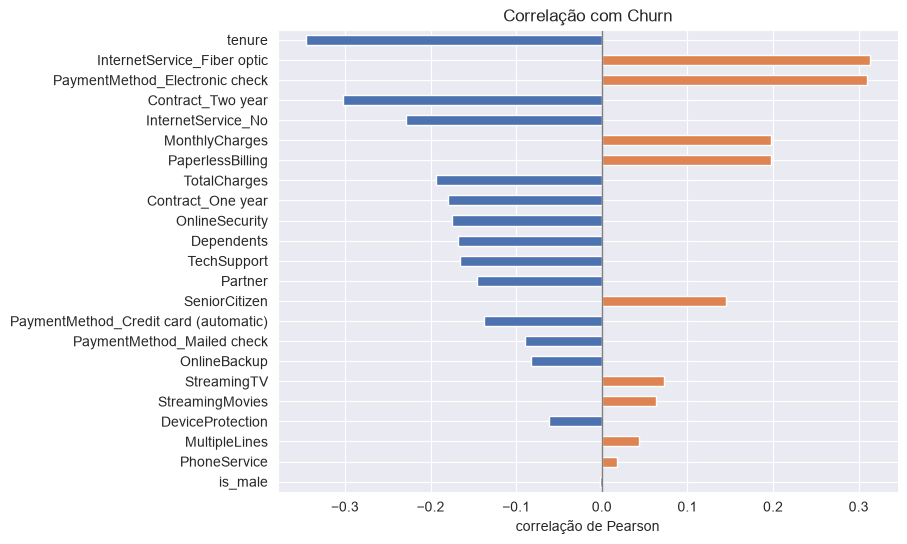

,corr_churn
StreamingTV,0.0724
StreamingMovies,0.0638
DeviceProtection,-0.0616
MultipleLines,0.0438
PhoneService,0.0179
is_male,-0.0022


In [138]:
corr_churn = X_enc.corrwith(y).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
corr_churn.plot.barh(ax=ax, color=np.where(corr_churn > 0, "#DD8452", "#4C72B0"))
ax.set(title="Correlação com Churn", xlabel="correlação de Pearson")
ax.axvline(0, color="gray", lw=1)
ax.invert_yaxis()
plt.show()
corr_churn.round(4).tail(6).to_frame("corr_churn")

### 3.4 Weight of Evidence (WoE) e Information Value (IV)

Para esse projeto, decidi trazer duas métricas que são usuais em *credit scoring*, WoE e IV, que são usadas para calcular o poder preditivo de uma variável, considerando um target. Para cada categoria (ou faixa, no caso das numéricas) de uma variável:

$$WoE = \ln\left(\frac{\%\ \text{dos churns que estão na categoria}}{\%\ \text{dos não churns que estão na categoria}}\right) \qquad IV = \sum_{\text{categorias}} (\%\ \text{churns} - \%\ \text{não churns}) \times WoE$$

- **WoE > 0**: a categoria concentra proporcionalmente mais churns que não churns (risco acima da média)
- **WoE < 0**: risco abaixo da média.

Em crédito, costuma-se usar a razão invertida (bons/maus). Neste projeto uso churn no numerador para que WoE positivo signifique mais churn.

- O **IV** resume o quanto as distribuições de churn e não churn diferem entre as categorias, ou seja, o poder de separação da variável **sozinha**
- Escala usual: \
IV < 0,02 sem poder \
0,02 – 0,1 fraco \
0,1 – 0,3 médio \
0,3–0,5 forte \
IV > 0,5 muito forte (em crédito, costuma ser sinal de vazamento a investigar)

**Observação:** \
As variáveis numéricas com muitos valores são discretizadas em decis. Usarei uma suavização de 0,5 nas contagens para evitar $\ln(0)$ em categorias sem churn ou sem não churn. As colunas de serviços são avaliados na forma binária usada pelos modelos (após juntar "No internet service" com "No"). O IV é calculado no treino e será usado só para orientar a escolha de um conjunto fixo de variáveis.

In [139]:
def tabela_woe(x, y, suavizacao=0.5):
    # n, taxa de churn, WoE e contribuição para o IV de cada categoria de x
    tab = pd.crosstab(x, y).reindex(columns=[0, 1], fill_value=0)
    tab.columns = ["nao_churn", "churn"]
    dist_churn = (tab["churn"] + suavizacao) / (tab["churn"] + suavizacao).sum()
    dist_nao = (tab["nao_churn"] + suavizacao) / (tab["nao_churn"] + suavizacao).sum()
    tab["n"] = tab["churn"] + tab["nao_churn"]
    tab["taxa_churn"] = tab["churn"] / tab["n"]
    tab["woe"] = np.log(dist_churn / dist_nao)
    tab["iv"] = (dist_churn - dist_nao) * tab["woe"]
    return tab[["n", "taxa_churn", "woe", "iv"]]


def discretizar(s, n_faixas=10):
    # Numéricas com muitos valores viram decis; as demais ficam como estão
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > n_faixas:
        return pd.qcut(s, n_faixas, duplicates="drop", precision=1)
    return s


def calcular_iv(df, y):
    return pd.Series({col: tabela_woe(discretizar(df[col]), y)["iv"].sum() for col in df.columns}).sort_values(ascending=False)


FAIXAS_IV = [0, 0.02, 0.1, 0.3, 0.5, np.inf]
ROTULOS_IV = ["inútil", "fraco", "médio", "forte", "muito forte"]

iv = calcular_iv(X, y)
tabela_iv = pd.DataFrame({"IV": iv.round(4), "poder preditivo": pd.cut(iv, FAIXAS_IV, labels=ROTULOS_IV, right=False)})
tabela_iv

,IV,poder preditivo
Contract,1.2357,muito forte
tenure,0.7802,muito forte
InternetService,0.6328,muito forte
PaymentMethod,0.4806,forte
MonthlyCharges,0.3631,forte
TotalCharges,0.3039,forte
PaperlessBilling,0.2167,médio
OnlineSecurity,0.1788,médio
Dependents,0.1620,médio
TechSupport,0.1590,médio


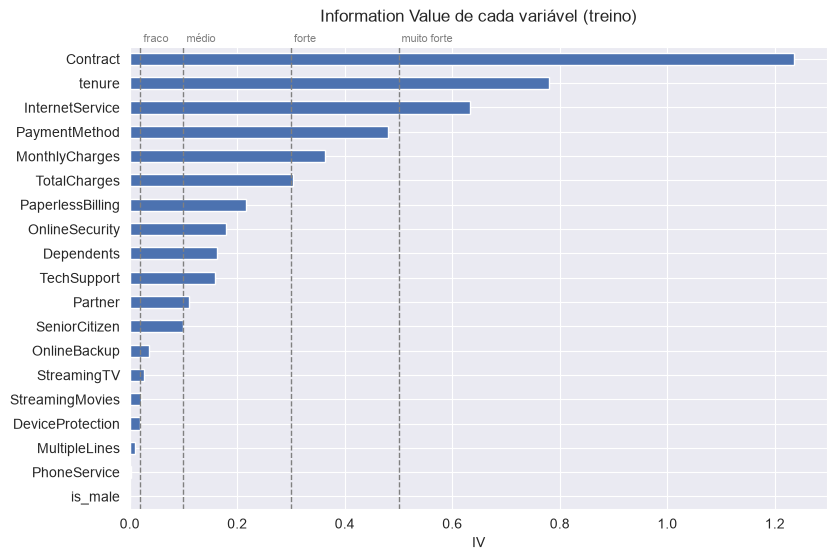

In [140]:
fig, ax = plt.subplots(figsize=(9, 6))
iv.plot.barh(ax=ax, color="#4C72B0")
for limiar, rotulo in zip(FAIXAS_IV[1:-1], ROTULOS_IV[1:]):
    ax.axvline(limiar, color="gray", ls="--", lw=1)
    ax.text(limiar, 1.01, f" {rotulo}", fontsize=8, color="gray", transform=ax.get_xaxis_transform())
ax.invert_yaxis()
ax.set_title("Information Value de cada variável (treino)", pad=18)
ax.set_xlabel("IV")
plt.show()

- O ranking das variáveis que se destacam pelo IV é praticamente o mesmo da correlação com o churn e da EDA
- Em crédito, IV > 0,5 levantaria suspeita de vazamento. Aqui os valores altos são coerentes: \
Em credit scoring, IVs acima de 0,5 seriam alarmantes pois prever inadimplência tem alta complexidade, e as boas variáveis costumam ficar entre 0,1 e 0,3. Um valor muito alto geralmente indica vazamento, ou seja, uma variável medida depois do evento, como “dias em atraso”, que já contém a resposta da inadimplência indiretamente. Nesse caso, os IVs altos de Contract, tenure e InternetService possuem categorias com altíssima taxa de churn, o que é justamente essa diferença que o IV mede, por isso ter um IV alto não é preocupante aqui.

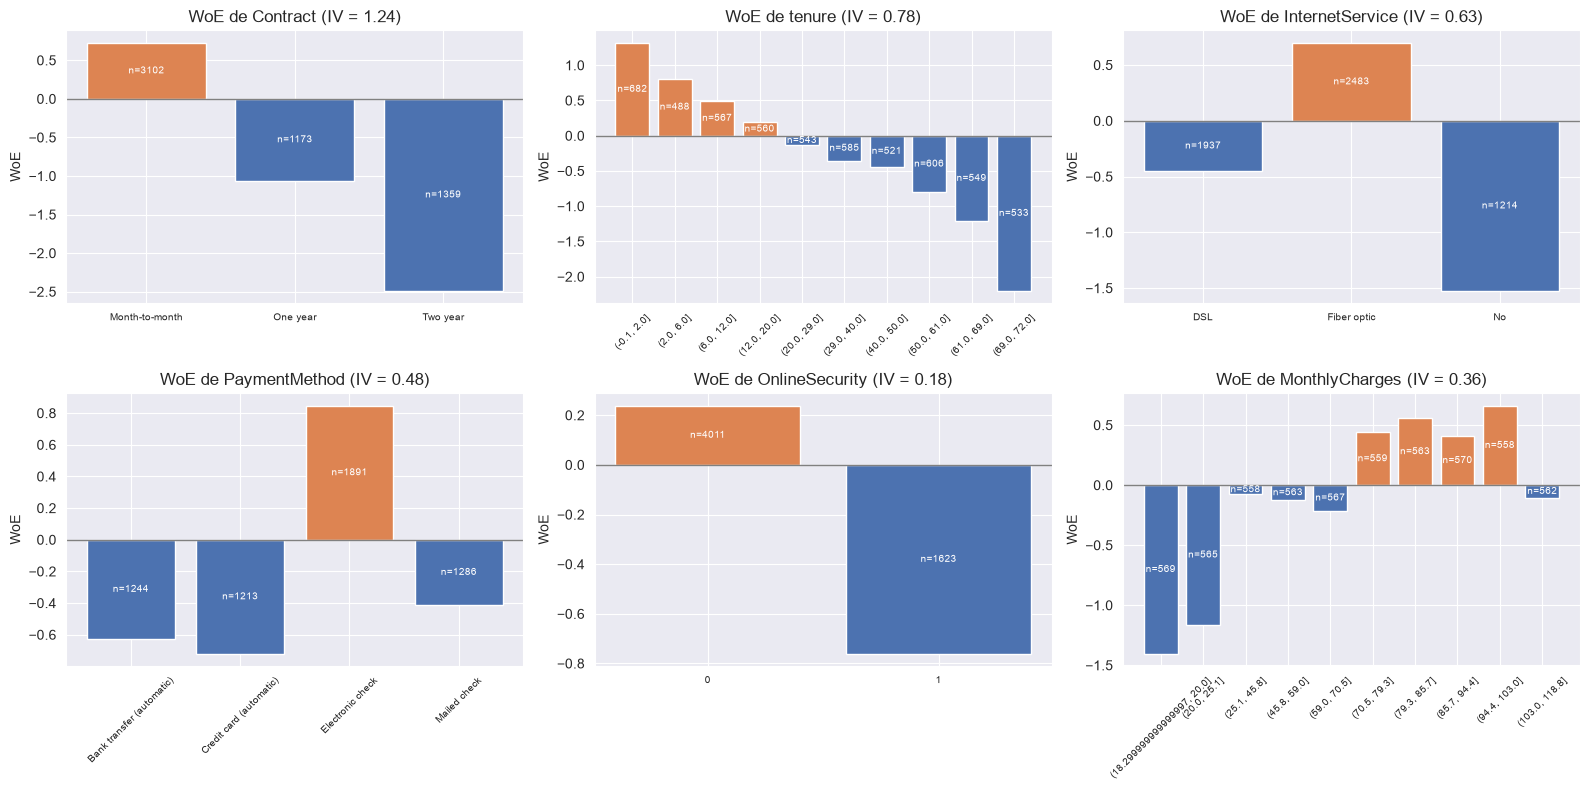

In [141]:
# WoE das categorias/faixas das variáveis mais relevantes
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for col, ax in zip(["Contract", "tenure", "InternetService", "PaymentMethod", "OnlineSecurity", "MonthlyCharges"], axes.ravel()):
    tab = tabela_woe(discretizar(X[col]), y)
    ax.bar(tab.index.astype(str), tab["woe"], color=np.where(tab["woe"] > 0, "#DD8452", "#4C72B0"))
    for xi, (woe, n) in enumerate(zip(tab["woe"], tab["n"])):
        ax.text(xi, woe / 2, f"n={n}", ha="center", va="center", fontsize=7, color="white")
    ax.axhline(0, color="gray", lw=1)
    ax.set(title=f"WoE de {col} (IV = {iv[col]:.2f})", ylabel="WoE")
    ax.tick_params(axis="x", rotation=45 if X[col].nunique() > 3 else 0, labelsize=7)
fig.tight_layout()
plt.show()

**Variáveis candidatas a remoção**
- **Relevância:** IV < 0,02 (sem poder preditivo sozinha), que são as mesmas que possuem menor correlação com o target.
- **Redundância:** `TotalCharges`, que tem IV alto, mas é quase totalmente explicada por `tenure` e `MonthlyCharges`

In [142]:
LIMIAR_IV = 0.02
POUCO_INFORMATIVAS = iv[iv < LIMIAR_IV].index.tolist()
REDUNDANTES = ["TotalCharges"]
REMOVER = REDUNDANTES + POUCO_INFORMATIVAS
print("Pouco informativas (IV < 0,02):", POUCO_INFORMATIVAS)
print("Redundantes:                   ", REDUNDANTES)

Pouco informativas (IV < 0,02): ['DeviceProtection', 'MultipleLines', 'PhoneService', 'is_male']
Redundantes:                    ['TotalCharges']


## 4. Criação de variáveis

Novas variáveis:

| Variável | Definição                                     | Motivação                                                                                                                               |
|---|-----------------------------------------------|-----------------------------------------------------------------------------------------------------------------------------------------|
| `n_servicos_adicionais` | nº de serviços adicionais de internet (0 a 6) | resume os 6 serviços. medir se a quantidade de serviços adicionais influencia no churn                                                  |
| `servicos_suporte` | `OnlineSecurity + TechSupport` (0 a 2)        | na EDA, a ausência desses dois serviços foi a mais associada a churn                                                                    |
| `log_tenure` | `log(1 + tenure)`                             | transformação, pois o risco cai rápido nos primeiros meses e depois estabiliza (relação não linear, dificultanto a regressão logística) |
| `variacao_mensalidade` | `MonthlyCharges − (TotalCharges / tenure)`    | compara o quanto o cliente paga hoje com o quanto ele pagou em média desde que entrou                                                   |
| `mensal_x_fibra` | contrato mensal **e** fibra óptica (0/1)      | interação entre os dois grupos de maior risco da EDA                                                                                    |

In [143]:
def criar_variaveis(df):
    df = df.copy()
    df["n_servicos_adicionais"] = df[SERVICOS_ADICIONAIS].sum(axis=1)
    df["servicos_suporte"] = df["OnlineSecurity"] + df["TechSupport"]
    df["log_tenure"] = np.log1p(df["tenure"])
    # Para tenure = 0 ainda não há histórico: a média é a própria mensalidade (variação 0)
    cobranca_media = (df["TotalCharges"] / df["tenure"]).where(df["tenure"] > 0, df["MonthlyCharges"])
    df["variacao_mensalidade"] = df["MonthlyCharges"] - cobranca_media
    df["mensal_x_fibra"] = ((df["Contract"] == "Month-to-month")
                            & (df["InternetService"] == "Fiber optic")).astype(int)
    return df


NOVAS_NUMERICAS = ["n_servicos_adicionais", "servicos_suporte", "log_tenure", "variacao_mensalidade"]
NOVAS_BINARIAS = ["mensal_x_fibra"]

X_fe = criar_variaveis(X)
X_fe[NOVAS_NUMERICAS + NOVAS_BINARIAS].describe().round(2)

,n_servicos_adicionais,servicos_suporte,log_tenure,variacao_mensalidade,mensal_x_fibra
count,5634.00,5634.00,5634.00,5634.00,5634.00
mean,2.06,0.58,3.04,-0.01,0.30
std,1.85,0.75,1.15,2.60,0.46
min,0.00,0.00,0.00,-18.90,0.00
25%,0.00,0.00,2.30,-1.18,0.00
50%,2.00,0.00,3.40,0.00,0.00
75%,3.00,1.00,4.03,1.13,1.00
max,6.00,2.00,4.29,19.13,1.00


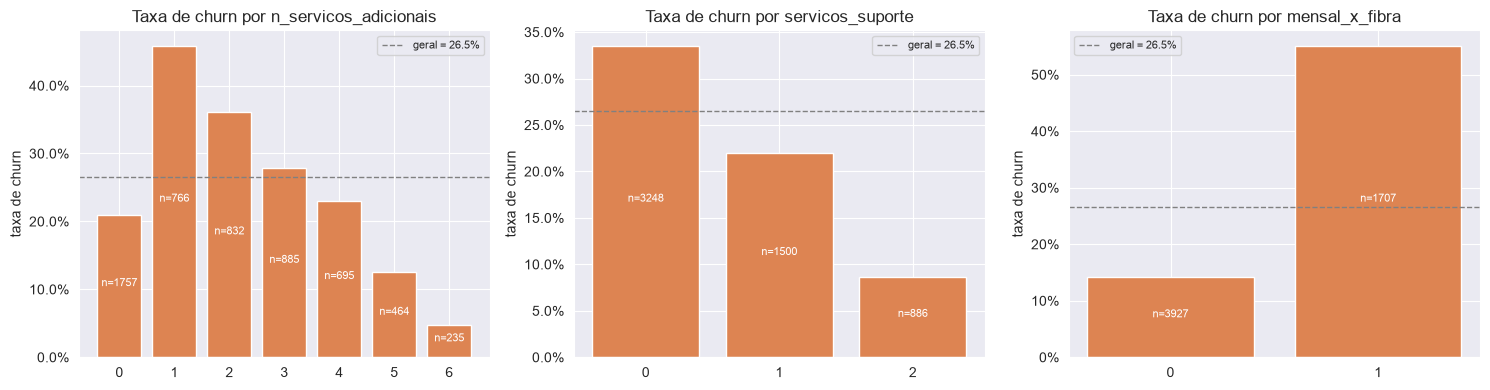

In [144]:
# Taxa de churn nas novas variáveis discretas (com o tamanho de cada grupo)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(["n_servicos_adicionais", "servicos_suporte", "mensal_x_fibra"], axes):
    tab = y.groupby(X_fe[col]).agg(n="size", taxa="mean")
    ax.bar(tab.index.astype(str), tab["taxa"], color="#DD8452")
    for xi, (taxa, n) in enumerate(zip(tab["taxa"], tab["n"])):
        ax.text(xi, taxa / 2, f"n={n}", ha="center", fontsize=8, color="white")
    ax.axhline(y.mean(), color="gray", ls="--", lw=1, label=f"geral = {y.mean():.1%}")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set(title=f"Taxa de churn por {col}", ylabel="taxa de churn")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [145]:
# variacao_mensalidade: taxa de churn por quintil
faixas = pd.qcut(X_fe["variacao_mensalidade"], q=5, duplicates="drop")
y.groupby(faixas, observed=True).agg(n="size", taxa="mean").round(3)

,n,taxa
variacao_mensalidade,,
"(-18.901, -1.531]",1127,0.308
"(-1.531, -0.3]",1127,0.165
"(-0.3, 0.276]",1126,0.369
"(0.276, 1.528]",1127,0.178
"(1.528, 19.125]",1127,0.306


In [146]:
# IV das variáveis criadas, comparado com o das originais de onde vieram
iv_novas = calcular_iv(X_fe[NOVAS_NUMERICAS + NOVAS_BINARIAS], y)
pd.DataFrame({"IV": iv_novas.round(4), "poder preditivo": pd.cut(iv_novas, FAIXAS_IV, labels=ROTULOS_IV, right=False)})

,IV,poder preditivo
mensal_x_fibra,0.8896,muito forte
log_tenure,0.7802,muito forte
n_servicos_adicionais,0.3249,forte
variacao_mensalidade,0.3162,forte
servicos_suporte,0.2745,médio


In [147]:
# Correlação com o churn x IV: a correlação só capta relação linear, o IV capta qualquer forma
pd.DataFrame({
    "corr_churn": X_fe[NOVAS_NUMERICAS + NOVAS_BINARIAS].corrwith(y).round(4),
    "IV": iv_novas.round(4),
}).sort_values("IV", ascending=False)

,corr_churn,IV
mensal_x_fibra,0.4261,0.8896
log_tenure,-0.3652,0.7802
n_servicos_adicionais,-0.0845,0.3249
variacao_mensalidade,0.0024,0.3162
servicos_suporte,-0.2068,0.2745


- `n_servicos_adicionais`: entre os clientes com internet, o churn cai conforme o número de serviços adicionais aumenta (45,8% com 1 serviço → 4,7% com 6). O grupo com 0 serviços tem churn baixo porque inclui os 1.214 clientes sem internet, que cancelam pouco.
- `servicos_suporte`: relação monótona e decrescente (33,5% → 22,0% → 8,7%.)
- `mensal_x_fibra`: o grupo com contrato mensal e fibra (n = 1.707) tem churn alto (~55%).
- `variacao_mensalidade`: não tem relação monótona com o churn. Os dois extremos (mensalidade bem acima ou bem abaixo da média histórica) têm churn ~31%, e o quintil central tem o maior churn (36,9%) porque concentra os clientes novos (`tenure` 0 ou 1, em que a variação é 0 por construção). Sozinha ela é pouco informativa.

**IV e correlação das variáveis criadas:**

A correlação de Pearson só mede relação linear, enquanto o IV mede o quanto a variável separa churn de não churn, qualquer que seja o formato da relação. Comparar as duas medidas mostra quais variáveis têm relação monótona com o churn e quais não têm.

- `mensal_x_fibra` tem IV 0,89 e correlação 0,43, os maiores entre as variáveis criadas e maiores que os de `InternetService_Fiber optic` (correlação 0,31). A interação entre as duas variáveis concentra o risco melhor que cada uma sozinha.
- `log_tenure` tem exatamente o mesmo IV de `tenure` (0,78), porque o IV é calculado por decis e o log não muda a ordem dos clientes. A correlação sobe pouco (−0,35 → −0,37), porque o log deixa a relação mais linear. Ou seja, não traz informação nova, só é uma forma mais conveniente para modelos lineares.
- `servicos_suporte` (IV 0,27, correlação −0,21) supera `OnlineSecurity` (0,18 e −0,17) e `TechSupport` (0,16 e −0,17). Somar os dois serviços concentra informação.
- `n_servicos_adicionais` tem IV 0,32, maior que o de qualquer serviço individual, mas correlação de apenas −0,08. A diferença vem da relação não monótona: o churn cai de 1 a 6 serviços, mas o grupo com 0 serviços tem churn baixo por incluir os clientes sem internet. A correlação linear não capta esse padrão, diferente do IV.
- `variacao_mensalidade` (0,32) é "forte" pelo IV, mas tem correlação praticamente nula (0,002). O IV capta a relação não monótona vista na tabela acima (extremos e quintil central com churn alto). Parte desse IV, porém, vem da concentração de clientes novos no quintil central, ou seja, é redundante com `tenure`.

## 5. Contribuição de cada conjunto de variáveis

Comparo quatro conjuntos de variáveis com validação cruzada nos mesmos 5 folds:

- **base**: todas as 19 variáveis originais (23 colunas após o one-hot)
- **reduzido**: base sem as variáveis com IV < 0,02 e sem `TotalCharges`
- **engenharia**: base + as 5 variáveis criadas na seção 4
- **engenharia_reduzido**: engenharia sem as variáveis removidas no reduzido

Para comparar os conjuntos uso dois modelos, um de regressão e um ensemble, para medir o efeito em diferentes famílias de modelos:

- **Regressão logística** (modelo linear) - não cria interações nem não linearidades sozinha, então depende diretamente das variáveis que recebe.
- **Random Forest** (ensemble de árvores) - aprende interações e cortes não lineares por conta própria.

Os modelos usam hiperparâmetros fixos. O ajuste de hiperparâmetros é feita no notebook 04. O objetivo neste momento é só comparar os conjuntos de variáveis. A métrica principal é a **precisão média (AP)**, que resume a curva precisão–sensibilidade da classe churn e não depende de limiar. A ROC-AUC e o F1 (limiar 0,5) são mostrados como complemento.

In [148]:
def conjunto(remover=(), novas=False):
    numericas = NUMERICAS + (NOVAS_NUMERICAS if novas else [])
    binarias = BINARIAS + (NOVAS_BINARIAS if novas else [])
    return {"numericas": [c for c in numericas if c not in remover],
            "binarias": [c for c in binarias if c not in remover],
            "categoricas": CATEGORICAS}


CONJUNTOS = {
    "base": conjunto(),
    "reduzido": conjunto(REMOVER),
    "engenharia": conjunto(novas=True),
    "engenharia_reduzido": conjunto(REMOVER, novas=True),
}

MODELOS = {
    "LogReg": LogisticRegression(max_iter=5000),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
}

pd.Series({nome: sum(len(v) for v in c.values()) for nome, c in CONJUNTOS.items()}, name="nº de variáveis")

base                   19
reduzido               14
engenharia             24
engenharia_reduzido    19
Name: nº de variáveis, dtype: int64

In [149]:
linhas = []
for nome_conj, c in CONJUNTOS.items():
    for nome_mod, modelo in MODELOS.items():
        pipe = Pipeline([("prep", fazer_preprocessador(**c)), ("modelo", modelo)])
        res = avaliar(pipe, X_fe, y).assign(modelo=nome_mod, configuração=nome_conj)
        linhas.append(res.rename_axis("fold").reset_index())
res_conj = pd.concat(linhas, ignore_index=True)
resumir(res_conj)

roc_auc             ap             f1
modelo       configuração                                                    
LogReg       base                 0.846 ± 0.014  0.661 ± 0.022  0.593 ± 0.034
             engenharia           0.849 ± 0.013  0.671 ± 0.017  0.597 ± 0.032
             engenharia_reduzido  0.849 ± 0.013  0.661 ± 0.019   0.583 ± 0.03
             reduzido             0.844 ± 0.013   0.65 ± 0.022  0.593 ± 0.031
RandomForest base                 0.844 ± 0.013  0.659 ± 0.026  0.569 ± 0.022
             engenharia           0.843 ± 0.011  0.654 ± 0.026  0.572 ± 0.019
             engenharia_reduzido  0.844 ± 0.011  0.653 ± 0.029  0.573 ± 0.024
             reduzido             0.843 ± 0.012  0.654 ± 0.026   0.572 ± 0.02

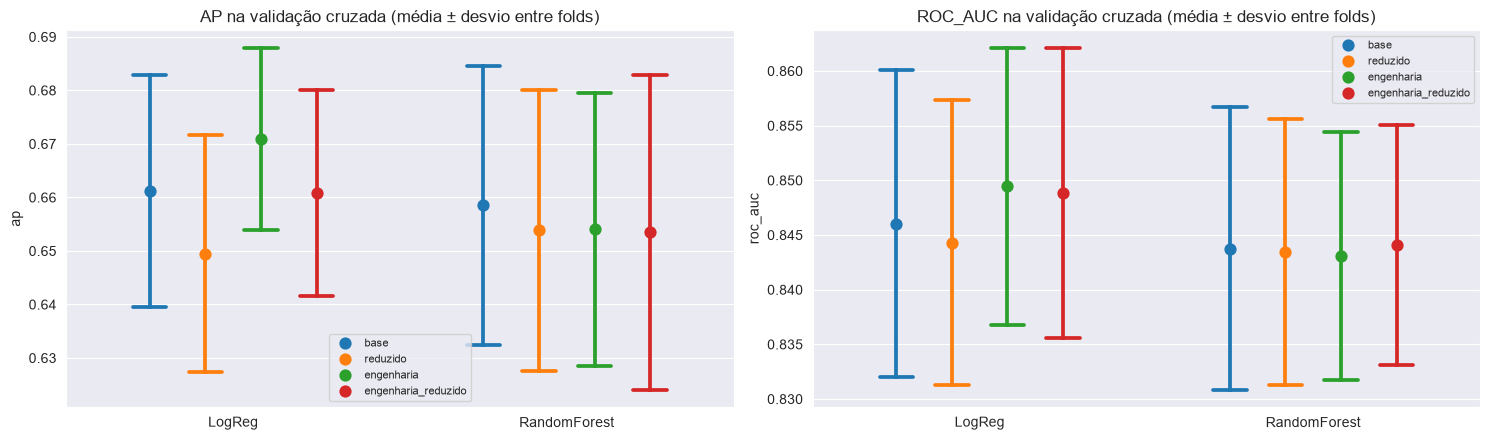

In [150]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for metrica, ax in zip(["ap", "roc_auc"], axes):
    sns.pointplot(data=res_conj, x="modelo", y=metrica, hue="configuração", errorbar="sd",
                  dodge=0.5, linestyle="none", capsize=0.1, ax=ax)
    ax.set(title=f"{metrica.upper()} na validação cruzada (média ± desvio entre folds)", xlabel="")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

O desvio entre folds é grande comparado às diferenças entre os conjuntos. Mas como todos os conjuntos usam **os mesmos folds**, dá para comparar fold a fold: calculo a diferença de AP de cada conjunto em relação ao `base` dentro de cada fold, o que elimina a variação que vem da dificuldade de cada fold.

In [151]:
ap = res_conj.pivot_table(index=["modelo", "fold"], columns="configuração", values="ap")
dif = ap.drop(columns="base").sub(ap["base"], axis=0)

pareado = pd.concat({
    "dif. média de AP": dif.groupby("modelo").mean(),
    "folds em que melhora": (dif > 0).groupby("modelo").sum(),
}, axis=1)
pareado.round(4)

dif. média de AP                               \
configuração       engenharia engenharia_reduzido reduzido   
modelo                                                       
LogReg                 0.0097             -0.0003  -0.0117   
RandomForest          -0.0045             -0.0050  -0.0046   

             folds em que melhora                               
configuração           engenharia engenharia_reduzido reduzido  
modelo                                                          
LogReg                          4                   3        1  
RandomForest                    2                   1        1

- **Seleção por IV (`reduzido`) não ajuda:** remover as 4 variáveis com IV < 0,02 e o `TotalCharges` piora a AP nos dois modelos (LogReg −0,012 e Random Forest −0,005, ambos melhores em só 1 de 5 folds).
- **Criação de variáveis (`engenharia`):** a regressão logística melhora. A AP sobe de 0,661 para 0,671, melhorando em 4 dos 5 folds, porque as variáveis criadas (`log_tenure`, `mensal_x_fibra`, contagens de serviços) dão ao modelo linear não linearidades e interações que ele não aprende sozinho.
- **Random Forest:** com a engenharia, a diferença é pequena (−0,005, ~1/5 do desvio entre folds) e sem direção consistente (melhora em 2 de 5 folds).
- **`engenharia_reduzido`:** a remoção das variáveis de IV baixo cancela o ganho da engenharia na regressão logística (volta para 0,661) e também não ajuda o Random Forest (−0,005).
- Na ROC-AUC o padrão é o mesmo, com diferenças ainda menores.

De forma geral, a **Feature Engineering** ajuda um pouco a Regressão Logística, que não cria interações por conta própria, e a **Feature Selection** por IV não ajuda nenhum dos dois.

### 5.1 Codificação WoE × one-hot na Regressão Logística

O WoE também pode ser usado como **codificação**. Cada categoria (ou faixa) é trocada pelo seu WoE. Para a regressão logística, isso pode ser benéfico, pois o WoE já está na escala do log-odds, então o modelo passa a ter uma relação linear com cada variável, mesmo quando a relação original não é monótona.

Como o WoE usa o alvo, ele é uma forma de *target encoding*, por isso precisa ser calculado só com o treino de cada fold para não haver data leakage.

Comparo três codificações, nos conjuntos `base` e `engenharia`:
- **one-hot**: o pré-processamento usado até agora
- **WoE nas categóricas**: WoE em `InternetService`, `Contract` e `PaymentMethod`; numéricas padronizadas
- **WoE em tudo**: numéricas discretizadas em decis e também codificadas por WoE (o "scorecard" clássico de crédito)

In [152]:
class WoEEncoder(BaseEstimator, TransformerMixin):
    # Troca cada categoria pelo seu WoE. Numéricas com mais de n_faixas valores viram decis antes.
    # Os cortes dos decis e os WoE são calculados só com os dados do fit (o treino de cada fold).
    def __init__(self, n_faixas=10):
        self.n_faixas = n_faixas

    def _faixas(self, X):
        X = X.copy()
        for col, cortes in self.cortes_.items():
            X[col] = np.digitize(X[col], cortes)
        return X

    def fit(self, X, y):
        X = pd.DataFrame(X)
        quantis = np.linspace(0, 1, self.n_faixas + 1)[1:-1]
        self.cortes_ = {col: np.unique(np.quantile(X[col], quantis))
                        for col in X.select_dtypes("number") if X[col].nunique() > self.n_faixas}
        Xf, y = self._faixas(X), pd.Series(np.asarray(y), index=X.index)
        self.woe_ = {col: tabela_woe(Xf[col], y)["woe"] for col in X.columns}
        return self

    def transform(self, X):
        # Categoria que não apareceu no fit recebe WoE 0 (risco médio)
        Xf = self._faixas(pd.DataFrame(X))
        return np.column_stack([Xf[col].map(self.woe_[col]).fillna(0.0).to_numpy(float) for col in self.woe_])


def fazer_preprocessador_woe(numericas, binarias, categoricas, woe_numericas=False):
    if woe_numericas:
        return ColumnTransformer([("woe", WoEEncoder(), numericas + categoricas),
                                  ("bin", "passthrough", binarias)])
    return ColumnTransformer([("num", StandardScaler(), numericas),
                              ("bin", "passthrough", binarias),
                              ("cat", WoEEncoder(), categoricas)])


print('Exemplo: WoE de Contract aprendido no treino inteiro')
WoEEncoder().fit(X[["Contract"]], y).woe_["Contract"].round(3)

Exemplo: WoE de Contract aprendido no treino inteiro


Contract
Month-to-month    0.726
One year         -1.061
Two year         -2.492
Name: woe, dtype: float64

In [153]:
CODIFICACOES = {
    "one-hot": lambda c: fazer_preprocessador(**c),
    "WoE nas categóricas": lambda c: fazer_preprocessador_woe(**c),
    "WoE em tudo": lambda c: fazer_preprocessador_woe(**c, woe_numericas=True),
}

linhas = []
for nome_conj in ["base", "engenharia"]:
    for nome_cod, prep in CODIFICACOES.items():
        pipe = Pipeline([("prep", prep(CONJUNTOS[nome_conj])), ("modelo", LogisticRegression(max_iter=5000))])
        res = avaliar(pipe, X_fe, y).assign(modelo=nome_conj, configuração=nome_cod)
        linhas.append(res.rename_axis("fold").reset_index())
res_woe = pd.concat(linhas, ignore_index=True)
resumir(res_woe).rename_axis(["conjunto", "codificação"])

roc_auc             ap             f1
conjunto   codificação                                                     
base       WoE em tudo          0.849 ± 0.014  0.672 ± 0.018  0.594 ± 0.036
           WoE nas categóricas  0.846 ± 0.014  0.661 ± 0.021  0.592 ± 0.033
           one-hot              0.846 ± 0.014  0.661 ± 0.022  0.593 ± 0.034
engenharia WoE em tudo          0.848 ± 0.014  0.671 ± 0.018  0.594 ± 0.039
           WoE nas categóricas   0.85 ± 0.012  0.671 ± 0.017  0.598 ± 0.033
           one-hot              0.849 ± 0.013  0.671 ± 0.017  0.597 ± 0.032

In [154]:
# Diferença de AP em relação ao one-hot, fold a fold (mesmos folds)
ap_woe = res_woe.pivot_table(index=["modelo", "fold"], columns="configuração", values="ap")
dif_woe = ap_woe.drop(columns="one-hot").sub(ap_woe["one-hot"], axis=0)
pd.concat({
    "dif. média de AP": dif_woe.groupby("modelo").mean(),
    "folds em que melhora": (dif_woe > 0).groupby("modelo").sum(),
}, axis=1).rename_axis("conjunto").round(4)

dif. média de AP                     folds em que melhora  \
configuração      WoE em tudo WoE nas categóricas          WoE em tudo   
conjunto                                                                 
base                   0.0107              0.0002                    4   
engenharia             0.0002              0.0003                    3   

                                  
configuração WoE nas categóricas  
conjunto                          
base                           2  
engenharia                     3

- **WoE nas categóricas é quase igual ao one-hot**. Não há ganho de informação.
- Já com **WoE em tudo, no conjunto `base`: +0,011 de AP** (melhora em 4 de 5 folds), chegando a 0,672, o mesmo nível do one-hot com as variáveis criadas (0,671). O ganho vem da discretização das numéricas. Com um WoE por decil, o modelo linear consegue representar a relação de variáveis não monótonas numéricas.
- No conjunto `engenharia`, o WoE não acrescenta nada.

**Decisão:** mantenho one-hot + variáveis criadas. O desempenho é o mesmo, funciona para todos os modelos (KNN e árvores não ganham nada com WoE), as variáveis continuam diretamente interpretáveis, e não é preciso escolher faixas nem ajustar uma codificação que usa o alvo em cada fold.

## 6. Decisão e salvamento

**Conjuntos escolhidos para o notebook 04: `base` e `engenharia`**

Reduzir variáveis, tanto por IV baixo ou por multicolinearidade (`TotalCharges`), não trouxe ganho em nenhum modelo. Por isso, descarto os conjuntos `reduzido` e `engenharia_reduzido` e levo dois conjuntos para o próximo notebook, de teste dos modelos.

- **`base`**: as 19 variáveis originais (23 colunas após o one-hot)
- **`engenharia`**: `base` + as 5 variáveis criadas (24 variáveis, 28 colunas após o one-hot)

Assim, no notebook 04 vou poder medir o ganho real das novas variáveis com os modelos já com hiperparâmetros ajustados e, quando for o caso, regularizados. Neste notebook, com hiperparâmetros fixos, a engenharia melhorou a regressão logística (+0,010 de AP, melhor em 4 de 5 folds) e não mudou o Random Forest. Os dois conjuntos serão avaliados em todos os modelos nos mesmos 5 folds, o que permite comparar o ganho fold a fold.

**Em comum aos dois conjuntos:**
- **Codificação:** binárias em 0/1 (notebook 01); one-hot com `drop="first"` em `InternetService`, `Contract` e `PaymentMethod`. A codificação WoE não melhorou o resultado quando as variáveis criadas estão presentes (seção 5.1).
- **Padronização:** `StandardScaler` nas numéricas (essencial para o KNN, recomendável para a regressão logística, indiferente para árvores), ajustado dentro do pipeline.
- **Removidas:** nenhuma. A remoção por IV piorou os resultados. `TotalCharges` continua no modelo mesmo sendo redundante, pois isso não prejudica a previsão. Portanto, os coeficientes de `tenure`, `MonthlyCharges`, `TotalCharges` e dos serviços devem ser interpretados com atenção devido a multicolinearidade.

**Só no conjunto `engenharia`:** `n_servicos_adicionais`, `servicos_suporte`, `log_tenure`, `variacao_mensalidade` e `mensal_x_fibra`.

**Observações** \
**WoE e IV** foram úteis para interpretar as variáveis e para justificar as variáveis criadas (que têm IV maior que as variáveis de onde vieram). Não foram úteis para selecionar variáveis, porque, como toda medida univariada, ignoram a informação que as variáveis carregam em conjunto.

**Ressalva:** as diferenças entre os conjuntos são pequenas e foram medidas com hiperparâmetros fixos. A conclusão desta etapa é que a criação de variáveis ajuda pouco e principalmente o modelo linear, e a seleção não ajuda. O notebook 04 vai mostrar se esse ganho se mantém com os modelos ajustados.

In [155]:
CONJUNTOS_ESCOLHIDOS = ["base", "engenharia"]

# Conjuntos de variáveis escolhidos (usados pelos próximos notebooks)
with open("../data/processed/feature_set.json", "w", encoding="utf-8") as f:
    json.dump({nome: CONJUNTOS[nome] for nome in CONJUNTOS_ESCOLHIDOS}, f, indent=2, ensure_ascii=False)

# Treino e teste com as variáveis criadas (regras fixas: o teste não influencia nenhuma decisão)
# Os dois conjuntos usam estes arquivos: o `base` só ignora as colunas novas
test = pd.read_csv("../data/processed/test.csv")
criar_variaveis(train).to_csv("../data/processed/train_fe.csv", index=False)
criar_variaveis(test).to_csv("../data/processed/test_fe.csv", index=False)

{nome: CONJUNTOS[nome] for nome in CONJUNTOS_ESCOLHIDOS}

{'base': {'numericas': ['tenure', 'MonthlyCharges', 'TotalCharges'],
  'binarias': ['is_male',
   'SeniorCitizen',
   'Partner',
   'Dependents',
   'PhoneService',
   'MultipleLines',
   'OnlineSecurity',
   'OnlineBackup',
   'DeviceProtection',
   'TechSupport',
   'StreamingTV',
   'StreamingMovies',
   'PaperlessBilling'],
  'categoricas': ['InternetService', 'Contract', 'PaymentMethod']},
 'engenharia': {'numericas': ['tenure',
   'MonthlyCharges',
   'TotalCharges',
   'n_servicos_adicionais',
   'servicos_suporte',
   'log_tenure',
   'variacao_mensalidade'],
  'binarias': ['is_male',
   'SeniorCitizen',
   'Partner',
   'Dependents',
   'PhoneService',
   'MultipleLines',
   'OnlineSecurity',
   'OnlineBackup',
   'DeviceProtection',
   'TechSupport',
   'StreamingTV',
   'StreamingMovies',
   'PaperlessBilling',
   'mensal_x_fibra'],
  'categoricas': ['InternetService', 'Contract', 'PaymentMethod']}}